### Retrospective Labellling - Data Preparation
* add node features from `edges_raw`, as this is retrospective labelling there is less concern on data leakage, as I am using the whole time set to classify the NA values within the timeset itself
* Created 3 csv files:
  * `train_raw_node_info`: train info but with added node features
  * `train_raw_removed_corr_var`: train info with added node features, but removed highly correlated and low variance features
  * `train_yj_robust_scaled`: train info but removed highly correlated and low variance features, transform highly skewed variables, and applied RobustScaled()

In [1]:
import numpy as np
import pandas as pd

from scipy import stats

import matplotlib.pyplot as plt


In [2]:
### Load data

train_raw = pd.read_csv("train.csv", header = 0)
edges_raw = pd.read_csv("txs_edgelist.csv", header = 0)


In [3]:
### Preview Data

print("train data:\n",train_raw.head(10), "\n")

# From Kaggle Page, edges is optional to use
print("edges:\n", edges_raw.head(10), "\n")

### Check which columns have NAs
train_raw.columns[train_raw.isna().any()].tolist()

train data:
         txId  time_step    feat_1    feat_2    feat_3     feat_4    feat_5  \
0  230425980          1 -0.171469 -0.184668 -1.201369  -0.121970 -0.043875   
1    5530458          1 -0.171484 -0.184668 -1.201369  -0.121970 -0.043875   
2  232022460          1 -0.172107 -0.184668 -1.201369  -0.121970 -0.043875   
3  232438397          1  0.163054  1.963790 -0.646376  12.409294 -0.063725   
4  230460314          1  1.011523 -0.081127 -1.201369   1.153668  0.333276   
5  230459870          1  0.961040 -0.081127 -1.201369   1.303743  0.333276   
6  230333930          1 -0.171264 -0.184668 -1.201369  -0.121970 -0.043875   
7  230595899          1 -0.171755 -0.184668 -1.201369  -0.046932 -0.043875   
8  232013274          1 -0.123127 -0.184668 -1.201369  -0.121970 -0.043875   
9  232029206          1 -0.005027  0.578941 -0.091383   4.380281 -0.063725   

     feat_6     feat_7    feat_8  ...  feat_157  feat_158  feat_159  feat_160  \
0 -0.113002  -0.061584 -0.162097  ... -0.600999

['label']

In [4]:
### Edgelist - is optional use, leave to the back burner for now

print("check for self-payments:", len(edges_raw[edges_raw["txId1"] == edges_raw["txId2"]]))

print("check for duplicates payments")
check = edges_raw.groupby(by = ["txId1", "txId2"], as_index = False).size()
check = check[check["size"]> 1]

print(check)

check for self-payments: 0
check for duplicates payments
Empty DataFrame
Columns: [txId1, txId2, size]
Index: []


Add Node Features into tabular data

In [5]:
edges = edges_raw.drop_duplicates(subset=['txId1', 'txId2'])
edges = edges[edges['txId1'] != edges['txId2']]

in_deg = edges['txId2'].value_counts()
out_deg = edges['txId1'].value_counts()

node_cols = ['in_degree', 'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume']

train_raw['in_degree'] = train_raw['txId'].map(in_deg).fillna(0).astype('float32')
train_raw['out_degree'] = train_raw['txId'].map(out_deg).fillna(0).astype('float32')
train_raw['total_degree'] = train_raw['in_degree'] + train_raw['out_degree']
train_raw['degree_ratio'] = (train_raw['in_degree'] + 1.0) / (train_raw['out_degree'] + 1.0)

# Total transaction volume per time_step across the whole network
step_vol = train_raw['time_step'].value_counts()
train_raw['timestep_tx_volume'] = train_raw['time_step'].map(step_vol).astype('float32')

print("train_raw shape with graph features:", train_raw.shape)

train_raw shape with graph features: (141772, 173)


Remove low variance variables

In [6]:
feat_cols = [f'feat_{i}' for i in range(1, 166)] + node_cols

# Calculate variance strictly on training data (to prevent data leakage)
variances = train_raw[feat_cols].var()
low_var_cols = variances[variances < 1e-4].index.tolist()

print(f"Number of near-zero variance features (< 0.0001): {len(low_var_cols)}")
print("Columns:", low_var_cols)

Number of near-zero variance features (< 0.0001): 0
Columns: []


Remove highly correlated variables

In [7]:
# 1. Compute absolute correlation matrix on labeled training features
corr_matrix = train_raw[feat_cols].corr().abs()

# 2. Compute how strongly each feature correlates with the target 'label'
target_corr = train_raw[feat_cols].apply(lambda x: x.corr(train_raw['label'])).abs()
#print(type(target_corr))

# 3. Inspect only the upper triangle of the correlation matrix (to avoid checking pairs twice)
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
#print(upper_tri)

# 4. Find pairs with correlation > 0.95 and drop the weaker feature
threshold = 0.95
cols_to_drop = set()

for col in upper_tri.columns:
    # For every column, check through the rows if there is 1 row that > threshold => collect index (name)
    high_corr_partners = upper_tri.index[upper_tri[col] > threshold].tolist()
    
    for partner in high_corr_partners:
        if col not in cols_to_drop and partner not in cols_to_drop:
            #if col or partner is alr slated to drop - dont need to continue

            # Keep the feature that has a higher correlation with the target label
            if target_corr[col] < target_corr[partner]:
                cols_to_drop.add(col)
            else:
                cols_to_drop.add(partner)

cols_to_drop = sorted(list(cols_to_drop))
print(f"Found {len(cols_to_drop)} redundant features with correlation > {threshold}")
print("Features to drop:", cols_to_drop)

cols_to_drop = cols_to_drop + low_var_cols

# 5. Create reduced feature list for modeling
selected_features = [c for c in feat_cols if c not in cols_to_drop]
print(f"Original features: {len(feat_cols)} -> Remaining features: {len(selected_features)}")

Found 63 redundant features with correlation > 0.95
Features to drop: ['feat_1', 'feat_100', 'feat_101', 'feat_104', 'feat_11', 'feat_111', 'feat_116', 'feat_122', 'feat_128', 'feat_13', 'feat_135', 'feat_139', 'feat_14', 'feat_140', 'feat_146', 'feat_152', 'feat_159', 'feat_165', 'feat_17', 'feat_19', 'feat_21', 'feat_26', 'feat_27', 'feat_28', 'feat_29', 'feat_30', 'feat_31', 'feat_33', 'feat_34', 'feat_37', 'feat_39', 'feat_40', 'feat_41', 'feat_43', 'feat_44', 'feat_46', 'feat_49', 'feat_51', 'feat_57', 'feat_58', 'feat_6', 'feat_60', 'feat_61', 'feat_62', 'feat_65', 'feat_66', 'feat_67', 'feat_68', 'feat_69', 'feat_72', 'feat_73', 'feat_74', 'feat_78', 'feat_79', 'feat_8', 'feat_81', 'feat_84', 'feat_85', 'feat_87', 'feat_9', 'feat_92', 'feat_94', 'feat_99']
Original features: 170 -> Remaining features: 107


Identify and treat Skewed Data

Numeric features checked: 170
Features with |skew| > 1.5: 104


,skewness,abs_skewness,suggest_yj_at_1_5
feat_34,241.507494,241.507494,True
feat_36,230.982966,230.982966,True
feat_37,226.713202,226.713202,True
feat_35,220.207320,220.207320,True
feat_73,158.242598,158.242598,True
feat_72,153.672357,153.672357,True
feat_71,140.100498,140.100498,True
feat_14,126.387082,126.387082,True
out_degree,125.412910,125.412910,True
feat_162,122.823848,122.823848,True


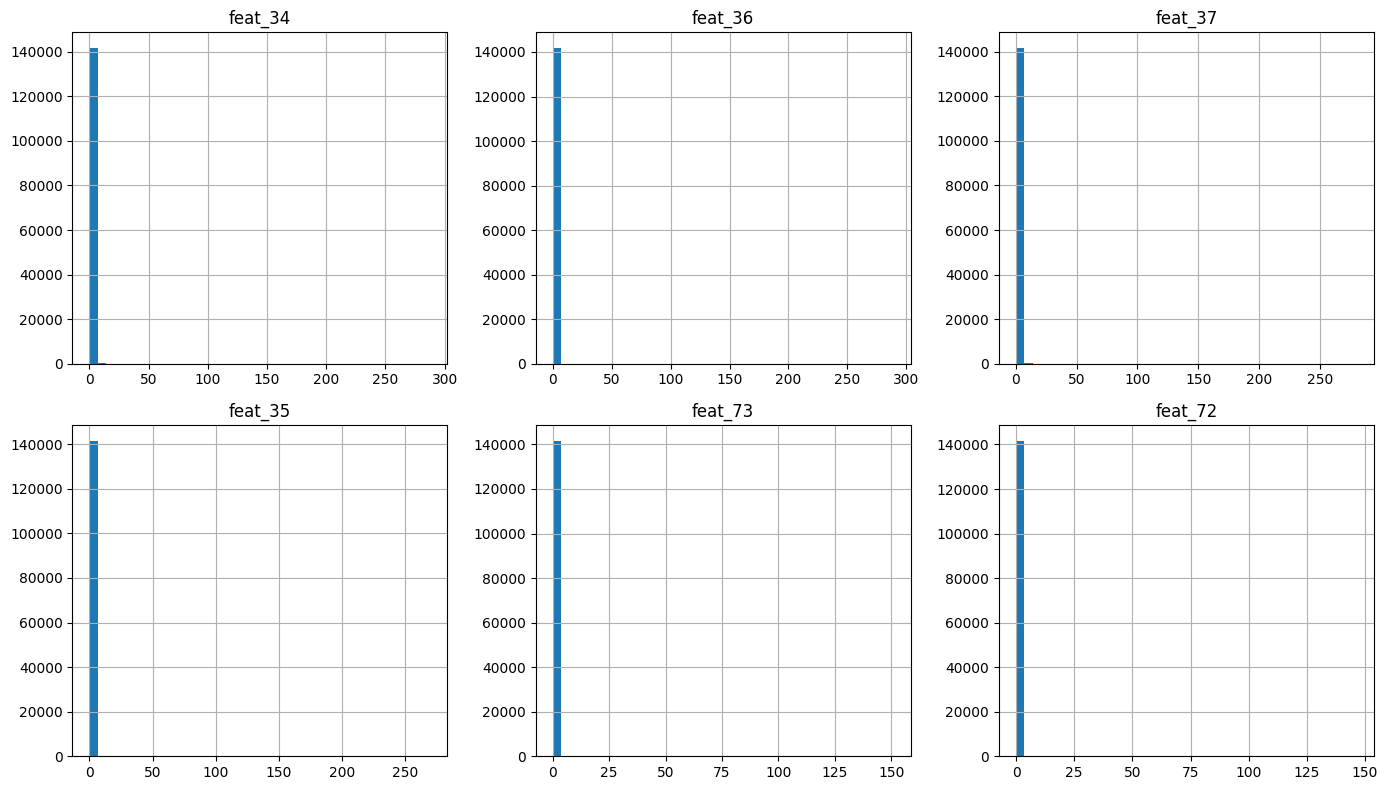

In [8]:
# Identify numeric predictors while excluding identifiers, time and target.
# The optional graph features created above are included automatically.
excluded_cols = {"txId", "index", "label", "time_step"}
feature_cols = [
    c for c in train_raw.select_dtypes(include=np.number).columns
    if c not in excluded_cols
]

# Distribution diagnostics on training predictors. These are descriptive only;
# the transformer below re-detects skewness inside each fit/fold.
skewness = train_raw[feature_cols].skew(axis=0, skipna=True)
skew_summary = pd.DataFrame({
    "skewness": skewness,
    "abs_skewness": skewness.abs(),
    "suggest_yj_at_1_5": skewness.abs() > 1.5,
}).sort_values("abs_skewness", ascending=False)
print(f"Numeric features checked: {len(feature_cols)}")
print(f"Features with |skew| > 1.5: {(skewness.abs() > 1.5).sum()}")
display(skew_summary.head(20))

# Optional: inspect the most skewed features.
most_skewed = skew_summary.head(6).index.tolist()
train_raw[most_skewed].hist(bins=40, figsize=(14, 8), layout=(2, 3))
plt.tight_layout()
plt.show()


In [9]:
cols_to_check = skew_summary.head(20).index

def most_common_value(s):
    counts = s.value_counts(dropna=True)
    return counts.index[0] if not counts.empty else np.nan

diagnostics = pd.DataFrame({
    "zero_fraction": train_raw[cols_to_check].eq(0).mean(),
    "most_common_fraction": train_raw[cols_to_check].apply(
        lambda s: s.value_counts(normalize=True, dropna=True).iloc[0]
        if s.notna().any() else np.nan
    ),
    "most_common_value": train_raw[cols_to_check].apply(most_common_value),
    "unique_values": train_raw[cols_to_check].nunique(),
    "p50": train_raw[cols_to_check].quantile(0.50),
    "p95": train_raw[cols_to_check].quantile(0.95),
    "p99": train_raw[cols_to_check].quantile(0.99),
    "max": train_raw[cols_to_check].max(),
}).sort_values("most_common_fraction", ascending=False)

display(diagnostics)

,zero_fraction,most_common_fraction,most_common_value,unique_values,p50,p95,p99,max
feat_15,0.000000,0.999309,-0.013282,26,-0.013282,-0.013282,-0.013282,119.477578
feat_70,0.000000,0.972921,-0.017032,1795,-0.017032,-0.017032,-0.016909,152.188806
feat_36,0.000000,0.963963,-0.023045,2809,-0.023045,-0.023045,0.065634,289.204388
feat_34,0.000000,0.871738,-0.024669,4269,-0.024669,-0.024651,-0.018820,287.891515
feat_35,0.000000,0.845350,-0.031272,5666,-0.031272,-0.031236,0.007437,269.701184
feat_37,0.000000,0.845350,-0.026215,6853,-0.026215,-0.026177,0.011019,280.566222
feat_14,0.000000,0.789606,-0.042955,216,-0.042955,0.078513,0.382182,265.263236
feat_5,0.000000,0.789437,-0.043875,221,-0.043875,0.075226,0.372976,260.090707
feat_161,0.000000,0.780316,-0.087490,228,-0.087490,0.123979,0.662264,251.849028
feat_10,0.000000,0.747475,-0.049707,35262,-0.049707,0.014381,0.676641,189.186944


Treatment of Highly skewed data (>1.5), and RobustScaler for all variables

In [10]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import PowerTransformer, RobustScaler
from sklearn.pipeline import Pipeline

class ConditionalYeoJohnson(BaseEstimator, TransformerMixin):
    """Apply Yeo-Johnson only to columns with |training skew| above threshold."""
    def __init__(self, skew_threshold=1.5):
        self.skew_threshold = skew_threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        # Ignore non-finite values for skew estimation; impute separately if needed.
        self.skewness_ = stats.skew(X, axis=0, nan_policy="omit", bias=False)
        self.skewness_ = np.nan_to_num(self.skewness_, nan=0.0)
        self.skewed_indices_ = np.flatnonzero(np.abs(self.skewness_) > self.skew_threshold)
        self.power_transformers_ = {}
        for j in self.skewed_indices_:
            pt = PowerTransformer(method="yeo-johnson", standardize=False)
            pt.fit(X[:, [j]])
            self.power_transformers_[j] = pt
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Input feature count differs from fitted data")
        for j, pt in self.power_transformers_.items():
            X[:, [j]] = pt.transform(X[:, [j]])
        return X

# Compose this with the estimator in a Pipeline during validation/search.
# That ensures skew selection, Yeo-Johnson parameters and scaling are refit
# using only each training fold.
preprocessor = Pipeline([
    ("conditional_yj", ConditionalYeoJohnson(skew_threshold=1.5)),
    ("robust_scale", RobustScaler()),
])

# Example final-fit matrices (use only after selecting a model/settings).
# If you have NA values in predictors, add SimpleImputer(strategy="median")
# as the first Pipeline step and fit it inside each fold as well.
X_train_raw = train_raw[feature_cols].copy()
X_train_transformed = preprocessor.fit_transform(X_train_raw)
print("Training features selected for Yeo-Johnson:", len(preprocessor.named_steps["conditional_yj"].skewed_indices_))
print("Transformed shapes:", X_train_transformed.shape)


Training features selected for Yeo-Johnson: 104
Transformed shapes: (141772, 170)


In [11]:
metadata_cols = [
    c for c in ["txId", "time_step", "label"]
    if c in train_raw.columns
]

# add node features to raw data as well:
train_raw_node_info = train_raw.copy()

train_raw_node_info.to_csv("train_raw_node_info.csv", index=False)

# Raw retained features, plus unchanged metadata
train_raw_selected = train_raw[metadata_cols + selected_features].copy()
train_raw_selected.to_csv("train_raw_removed_corr_var.csv", index=False)

# Recover the feature names and row index
transformed_feature_cols = feature_cols

X_train_transformed_df = pd.DataFrame(
    X_train_transformed,
    columns=transformed_feature_cols,
    index=train_raw.index
)

# Keep everything not transformed, such as txId, time_step and label
other_cols = [c for c in train_raw.columns if c not in feature_cols]

train_transformed_full = pd.concat(
    [train_raw[other_cols], X_train_transformed_df],
    axis=1
)

train_transformed_full = train_transformed_full[train_raw.columns]
train_transformed_full.to_csv("train_yj_robust_scaled.csv", index=False)

Include node_degree elements into train_raw as well

In [13]:
print(train_raw.columns)

print(train_raw_selected.columns)
print(train_transformed_full.columns)

Index(['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_6', 'feat_7', 'feat_8',
       ...
       'feat_162', 'feat_163', 'feat_164', 'feat_165', 'label', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=173)
Index(['txId', 'time_step', 'label', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_7', 'feat_10', 'feat_12',
       ...
       'feat_160', 'feat_161', 'feat_162', 'feat_163', 'feat_164', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=110)
Index(['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_6', 'feat_7', 'feat_8',
       ...
       'feat_162', 'feat_163', 'feat_164', 'feat_165', 'label', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=173)
